In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# From a target to a probe track

You want to record from one brain region. Where does the probe go in, what will it pass through,
and, after the experiment, where did it actually end up? This tutorial plans an insertion from a
target (steps 1–6) and then compares the plan with a track reconstructed from histology
(steps 7–10). You can stop after either half.

The target, the angles and the reconstructed track are stand-ins; replace them with your own. For
the `Trajectory` and `Insertion` objects used here, see
[Describe a probe insertion and list the regions it crosses](../how-to/work-with-probe-insertions.qmd).

## 1. Load the in vivo atlas

The Allen atlas was built from fixed brains, which shrink. Coordinates measured from bregma on a
live mouse need a version of the atlas scaled back to in vivo size. `NeedlesAtlas` is one such
scaling and `MRITorontoAtlas` is the other; see
[Atlas spaces and transforms](../explanation/atlas-spaces.qmd) for how they differ.

In [2]:
from iblatlas.atlas import NeedlesAtlas

ba = NeedlesAtlas()

## 2. Pick a target

The target is a point in the posterior thalamus, in metres from bregma (ML, AP, DV). See
[Coordinates and volumes](../explanation/coordinates-and-volumes.qmd).

In [3]:
import numpy as np

target = np.array([-0.0015, -0.002, -0.0035])  # ML -1.5, AP -2.0, DV -3.5 mm
ba.regions.id2acronym(ba.get_labels(target, mapping='Beryl'))

array(['PO'], dtype=object)

## 3. Choose angles and find the entry point

θ is the polar angle, the tilt from vertical, and φ the azimuth; a φ other than 0 or 180 takes the
probe out of the coronal plane. See the field table in
[Describe a probe insertion and list the regions it crosses](../how-to/work-with-probe-insertions.qmd).

Build a line through the target in that direction, find where it meets the brain surface, and
describe the probe as an `Insertion` from that entry point. The entry point lies on the atlas voxel
grid, so the tip lands within a voxel of the target. Note that `Insertion.from_dict` takes
micrometres; everything else here is in metres.

In [4]:
from iblatlas.atlas import Insertion, Trajectory, sph2cart

theta, phi = 15, 210  # degrees
trajectory = Trajectory(vector=sph2cart(1, theta, phi), point=target)
entry = Insertion.get_brain_entry(trajectory, ba)
plan = Insertion(x=entry[0], y=entry[1], z=entry[2], phi=phi, theta=theta,
                 depth=np.linalg.norm(entry - target))
print(f'entry (µm): {np.round(plan.entry * 1e6)}, depth: {plan.depth * 1e6:.0f} µm')

entry (µm): [-2289. -2446.  -112.], depth: 3507 µm


## 4. List the regions it passes through

`plan.xyz` holds only the entry and the tip. Sample points between them, label each with the Beryl
mapping, and keep each region once in the order the probe crosses it, with the depth range in
micrometres from the entry. `root` marks fibre tracts and ventricles, which Beryl does not name; see
[Brain region mappings](../explanation/brain-region-mappings.qmd).

In [5]:
import pandas as pd


def regions_along(insertion, atlas, n=2000):
    """Beryl regions crossed from entry to tip, with start and end depth in µm."""
    depth = np.linspace(0, insertion.depth, n)
    xyz = insertion.entry + (insertion.tip - insertion.entry) * (depth / insertion.depth)[:, np.newaxis]
    acronyms = atlas.regions.id2acronym(atlas.get_labels(xyz, mapping='Beryl'))
    starts = np.r_[True, acronyms[1:] != acronyms[:-1]]
    start_um = depth[starts] * 1e6
    return pd.DataFrame({'region': acronyms[starts], 'start_um': start_um.round(),
                         'end_um': np.r_[start_um[1:], insertion.depth * 1e6].round()})


planned_regions = regions_along(plan, ba)
planned_regions

,region,start_um,end_um
0,VISam,0.0,39.0
1,VISa,39.0,56.0
2,VISam,56.0,88.0
3,VISa,88.0,837.0
4,root,837.0,998.0
5,CA1,998.0,1565.0
6,DG,1565.0,2033.0
7,CA3,2033.0,2065.0
8,DG,2065.0,2256.0
9,root,2256.0,2281.0


## 5. Show it on a slice

`tilted_slice` cuts the slice that contains the probe, following its tilt in AP, and returns the
image with its extent in metres. `plot_tilted_slice` wraps the same call.

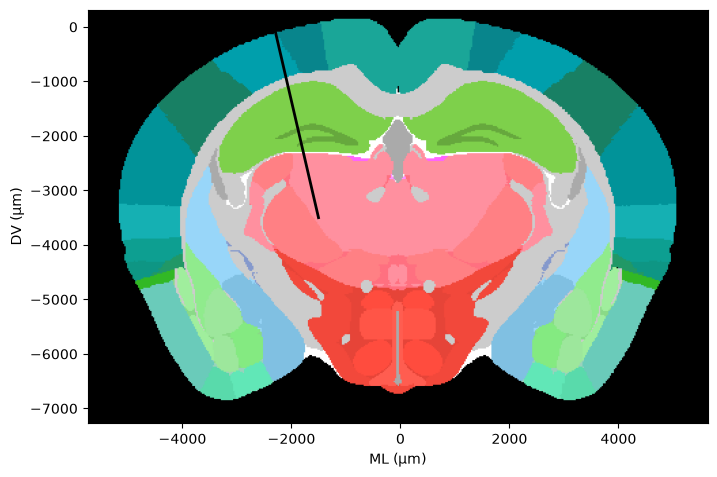

In [6]:
import matplotlib.pyplot as plt


def show_tracks(insertions, atlas, colours, ax):
    """The annotation slice along the first insertion, with every insertion drawn on it in µm."""
    tslice, width, height, _ = atlas.tilted_slice(insertions[0].xyz, axis=1, volume='annotation')
    ax.imshow(tslice, extent=np.r_[width, height] * 1e6)
    for insertion, colour in zip(insertions, colours):
        ax.plot(insertion.xyz[:, 0] * 1e6, insertion.xyz[:, 2] * 1e6, color=colour, lw=2)
    ax.set(xlabel='ML (µm)', ylabel='DV (µm)')


fig, ax = plt.subplots(figsize=(8, 6))
show_tracks([plan], ba, ['k'], ax)

## 6. Why the atlas choice matters

Label the same planned coordinates in the unscaled `AllenAtlas`. The cortical regions differ, and
the deeper boundaries move by tens to hundreds of micrometres. Use the atlas your coordinates were
made in; see [Atlas spaces and transforms](../explanation/atlas-spaces.qmd).

In [7]:
from iblatlas.atlas import AllenAtlas

pd.concat({'NeedlesAtlas': planned_regions, 'AllenAtlas': regions_along(plan, AllenAtlas())}, axis=1)

NeedlesAtlas                  AllenAtlas                 
         region start_um  end_um     region start_um  end_um
0         VISam      0.0    39.0      VISpm      0.0   279.0
1          VISa     39.0    56.0      VISam    279.0   330.0
2         VISam     56.0    88.0      VISpm    330.0   391.0
3          VISa     88.0   837.0      VISam    391.0   409.0
4          root    837.0   998.0      VISpm    409.0   433.0
5           CA1    998.0  1565.0      VISam    433.0   847.0
6            DG   1565.0  2033.0       root    847.0  1030.0
7           CA3   2033.0  2065.0        CA1   1030.0  1624.0
8            DG   2065.0  2256.0         DG   1624.0  2349.0
9          root   2256.0  2281.0       root   2349.0  2402.0
10           LP   2281.0  2773.0         LP   2402.0  2944.0
11           PO   2773.0  3507.0         PO   2944.0  3507.0

## 7. After the experiment: load the reconstructed points

Points traced along the probe track in histology usually come out of the registration tool in Allen
CCF micrometres. Convert them with `ccf2xyz` on the same in vivo atlas. See
[Coordinates and volumes](../explanation/coordinates-and-volumes.qmd).

In [8]:
# Stand-in for 30 points traced along the track in a registration tool: CCF µm, (ML, AP, DV)
track_ccf_um = np.array([
    [3504, 7852, 795], [3484, 7834, 902], [3536, 7828, 1015], [3590, 7827, 1120], [3588, 7817, 1263],
    [3658, 7796, 1367], [3645, 7789, 1468], [3690, 7730, 1547], [3646, 7803, 1695], [3744, 7729, 1793],
    [3849, 7750, 1922], [3876, 7686, 2000], [3828, 7734, 2126], [3876, 7707, 2263], [3900, 7683, 2355],
    [3934, 7641, 2478], [3978, 7601, 2563], [3965, 7590, 2699], [4045, 7625, 2765], [4047, 7614, 2914],
    [4078, 7556, 3046], [4073, 7543, 3140], [4142, 7512, 3287], [4172, 7483, 3355], [4169, 7481, 3448],
    [4249, 7496, 3613], [4248, 7483, 3653], [4287, 7500, 3825], [4336, 7421, 3918], [4339, 7412, 3994]])
track_points = ba.ccf2xyz(track_ccf_um)

## 8. Fit the track

`Insertion.from_track` fits a line through the points, takes the deepest point projected onto that
line as the tip, and intersects the line with the brain surface for the entry. φ is reported between
−180° and 180°, so −150° is the same direction as 210°. Because the tip is the deepest traced point,
a trace that stops short of the real tip gives a depth that is too short.

In [9]:
fit = Insertion.from_track(track_points, brain_atlas=ba)
print(f'entry (µm): {np.round(fit.entry * 1e6)}, tip (µm): {np.round(fit.tip * 1e6)}')
print(f'theta: {fit.theta:.1f}°, phi: {fit.phi:.1f}°, depth: {fit.depth * 1e6:.0f} µm')

entry (µm): [-2339. -2745.  -112.], tip (µm): [-1399. -2208. -3489.]
theta: 17.8°, phi: -150.3°, depth: 3546 µm


## 9. Compare plan and reality

Set the two region lists side by side and draw both tracks on the slice along the reconstructed
one. The tracks are drawn in ML and DV, so most of their difference in AP does not show in the
figure; the distance between the entry points gives it.

In [10]:
print(f'entry points are {np.linalg.norm(fit.entry - plan.entry) * 1e6:.0f} µm apart')
pd.concat({'planned': planned_regions, 'reconstructed': regions_along(fit, ba)}, axis=1).fillna('')

entry points are 303 µm apart


planned                  reconstructed                 
    region start_um  end_um        region start_um  end_um
0    VISam      0.0    39.0         VISpm      0.0   809.0
1     VISa     39.0    56.0         VISam    809.0   837.0
2    VISam     56.0    88.0          root    837.0  1013.0
3     VISa     88.0   837.0           CA1   1013.0  1563.0
4     root    837.0   998.0            DG   1563.0  2237.0
5      CA1    998.0  1565.0          root   2237.0  2246.0
6       DG   1565.0  2033.0            DG   2246.0  2262.0
7      CA3   2033.0  2065.0          root   2262.0  2313.0
8       DG   2065.0  2256.0            LP   2313.0  2863.0
9     root   2256.0  2281.0            PO   2863.0  3546.0
10      LP   2281.0  2773.0                               
11      PO   2773.0  3507.0

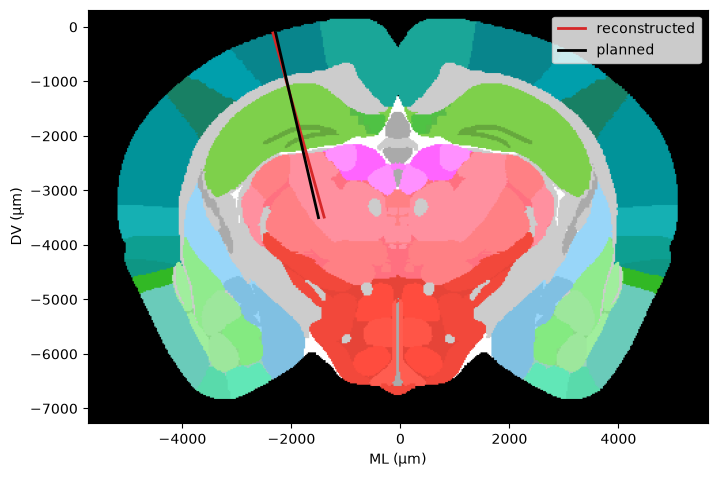

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
show_tracks([fit, plan], ba, ['tab:red', 'k'], ax)
ax.legend(['reconstructed', 'planned']);

## 10. Where next

- [Describe a probe insertion and list the regions it crosses](../how-to/work-with-probe-insertions.qmd)
- [Show the slice along my probe](../how-to/show-the-slice-along-a-probe.ipynb)
- [How far are these cells from the track?](../how-to/find-cell-distances-to-a-probe.ipynb)
- [Atlas spaces and transforms](../explanation/atlas-spaces.qmd)
- [Show one value per region on slices](../how-to/plot-values-on-slices.ipynb)